# 01 – Exploratory data analysis

Goal: understand size, class balance, missing values and group base rates before modeling.

This notebook prints **aggregates only, never raw rows**: outputs are committed to git, and Kaggle's terms restrict redistributing the data.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from credit_risk.config import MODEL_INPUTS, TARGET
from credit_risk.data import clean, load_raw

df = clean(load_raw())
print(f"{len(df):,} applicants, default rate {df[TARGET].mean():.2%}")

307,511 applicants, default rate 8.07%


## Missing values
LightGBM handles missing values natively; logistic regression needs imputation.

In [2]:
missing = df[MODEL_INPUTS].isna().mean().sort_values(ascending=False)
missing[missing > 0].map("{:.1%}".format)

ext_source_1       56.4%
ext_source_3       19.8%
years_employed     18.0%
ext_source_2        0.2%
amt_goods_price     0.1%
amt_annuity         0.0%
dtype: str

## The employment placeholder
`years_employed` is missing where the raw data had the 365243 placeholder. Which income types are these applicants?

In [3]:
df.groupby(df["years_employed"].isna().rename("years_employed_missing"))["income_type"].value_counts().unstack(0, fill_value=0)

years_employed_missing,False,True
income_type,,
Businessman,10,0
Commercial associate,71617,0
Maternity leave,5,0
Pensioner,10,55352
State servant,21703,0
Student,18,0
Unemployed,0,22
Working,158774,0


## Numeric distributions

In [4]:
numeric = ["amt_income_total", "amt_credit", "amt_annuity", "amt_goods_price", "years_employed", "age_years"]
df[numeric].describe(percentiles=[0.05, 0.5, 0.95]).T.drop(columns=["min", "max"]).round(1)

,count,mean,std,5%,50%,95%
amt_income_total,307511.0,168797.9,237123.1,67500.0,147150.0,337500.0
amt_credit,307511.0,599026.0,402490.8,135000.0,513531.0,1350000.0
amt_annuity,307499.0,27108.6,14493.7,9000.0,24903.0,53325.0
amt_goods_price,307233.0,538396.2,369446.5,135000.0,450000.0,1305000.0
years_employed,252137.0,6.5,6.4,0.6,4.5,20.0
age_years,307511.0,43.9,11.9,25.8,43.1,63.5


## Strongest single signal: external credit scores
Default rate by decile of `ext_source_2` (1 = lowest score).

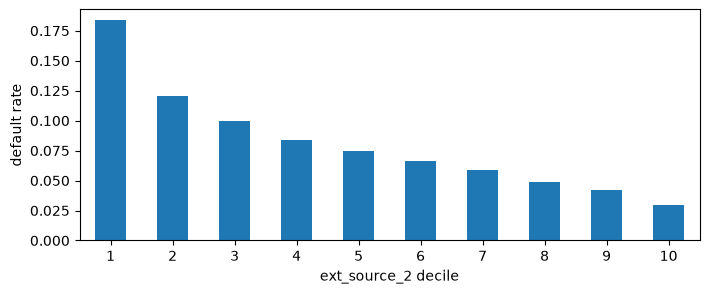

In [5]:
rate_by_decile = df.groupby(pd.qcut(df["ext_source_2"], 10, labels=range(1, 11)), observed=True)[TARGET].mean()
ax = rate_by_decile.plot.bar(figsize=(8, 3), rot=0, ylabel="default rate", xlabel="ext_source_2 decile")
plt.show()

## A debt-to-income style ratio
Payment-to-income = annuity / income. Does the default rate rise with it? (quintiles)

In [6]:
payment_to_income = df["amt_annuity"] / df["amt_income_total"]
df.groupby(pd.qcut(payment_to_income, 5), observed=True)[TARGET].mean().map("{:.2%}".format)

(-0.000776, 0.104]    7.20%
(0.104, 0.144]        7.83%
(0.144, 0.186]        8.13%
(0.186, 0.247]        8.70%
(0.247, 1.876]        8.52%
Name: defaulted, dtype: str

## Base rates by protected group
These columns are **not** model inputs. If default rates differ between groups, some fairness metrics will differ too, even for an accurate model.

In [7]:
age_band = pd.cut(df["age_years"], bins=[0, 30, 45, 60, 120], right=False,
                  labels=["<30", "30-44", "45-59", "60+"])
for name, group in [("gender", df["gender"]), ("age band", age_band),
                    ("family status", df["family_status"])]:
    summary = df.groupby(group, observed=True)[TARGET].agg(n="size", default_rate="mean")
    summary["default_rate"] = summary["default_rate"].map("{:.2%}".format)
    print(f"\n{name}\n{summary.to_string()}")


gender
             n default_rate
gender                     
F       202448        7.00%
M       105059       10.14%

age band
                n default_rate
age_years                     
<30         45186       11.44%
30-44      123737        9.00%
45-59      103287        6.56%
60+         35301        4.92%

family status
                           n default_rate
family_status                            
Civil marriage         29775        9.94%
Married               196432        7.56%
Separated              19770        8.19%
Single / not married   45444        9.81%
Unknown                    2        0.00%
Widow                  16088        5.82%


## Findings

1. **Imbalance.** 307,511 applicants, 8.07% defaulted. Approving everyone would be 91.9% "accurate"
   and catch zero defaults, which is why we use ROC-AUC, PR-AUC and calibration instead of accuracy.

2. **External scores dominate.** For all three `ext_source` scores, the default rate falls from
   18–20% in the lowest decile to ~3% in the highest. When a score is missing (56% for `ext_source_1`),
   the default rate is close to average (7.9–9.3%), so "missing" should be modeled as its own case,
   not silently filled with a typical value.

3. **The employment placeholder means "pensioner".** Of the 55,374 applicants with the 365243 placeholder,
   55,352 are pensioners and 22 are unemployed. The model's "not employed" flag is effectively a pensioner flag.

4. **That flag is an age proxy.** 83% of applicants aged 60+ are pensioners, versus under 1% of those under 45.
   So even with age removed from the model, `income_type = Pensioner` and the not-employed flag carry age
   information. The fairness audit has to check for this: leaving age out does not remove its signal.

5. **Payment-to-income is surprisingly weak.** Default rate only moves from 7.2% to 8.5% across quintiles,
   and not steadily. A likely reason (a hypothesis, not proven): Home Credit's own approval process already
   rejected unaffordable loans, so we only see a narrow, pre-filtered range. That is selection bias,
   the same reason we never see outcomes for rejected applicants.

6. **Base rates differ by group.** Men 10.1% vs women 7.0%; under 30: 11.4% vs 60+: 4.9%.
   An accurate, well-calibrated model will therefore approve these groups at different rates. The fairness
   write-up must separate "different outcomes because of different base rates" from "the model treats
   similar people differently".

7. **Heavy-tailed amounts.** Income has mean 169k vs median 147k with a long right tail. Tree models don't
   care, but for logistic regression we log-transform amounts so a few huge incomes don't dominate.
   Missing values in `amt_annuity` (12 rows) and `amt_goods_price` (278 rows) are negligible.

**Decisions for M1–M2:** log-transform amounts and add missing-value indicators for logistic regression;
let LightGBM handle missing values natively; track the pensioner flag as a known age proxy in the fairness audit.
